
Causal SHAP (paper-faithful) on: ../datasets/cv_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.6623, MAE=1.3549

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 4 features...
✓ PC completed -> CPDAG
Graph: 4 nodes, 2 edges

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i:
  diet_score            W=  1.557027   γ=0.268893
  sleep_duration        W=  1.514280   γ=0.261510
  family_history        W=  0.097514   γ=0.016840
  bmi                   W=  2.621693   γ=0.452757

Computing global Causal SHAP over 30 instances ...
  5/30
  10/30
  15/30
  20/30
  25/30
  30/30

-----------------------

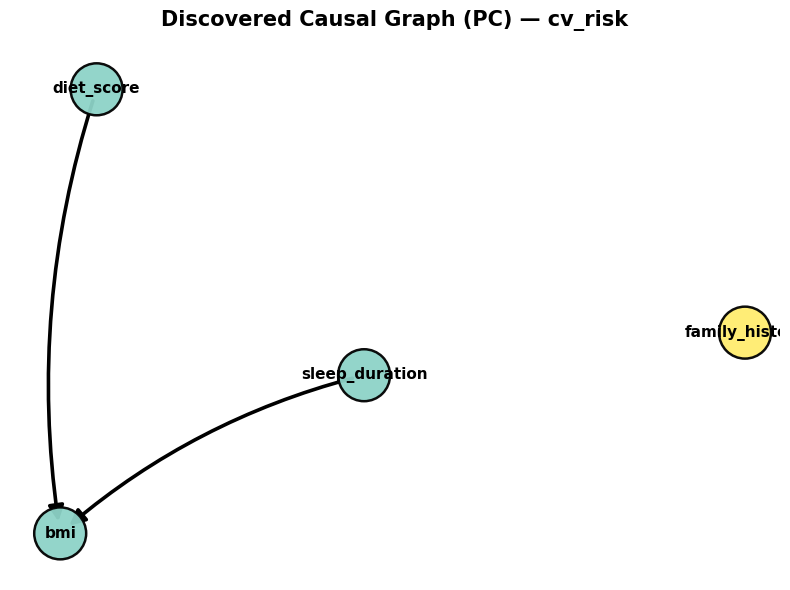

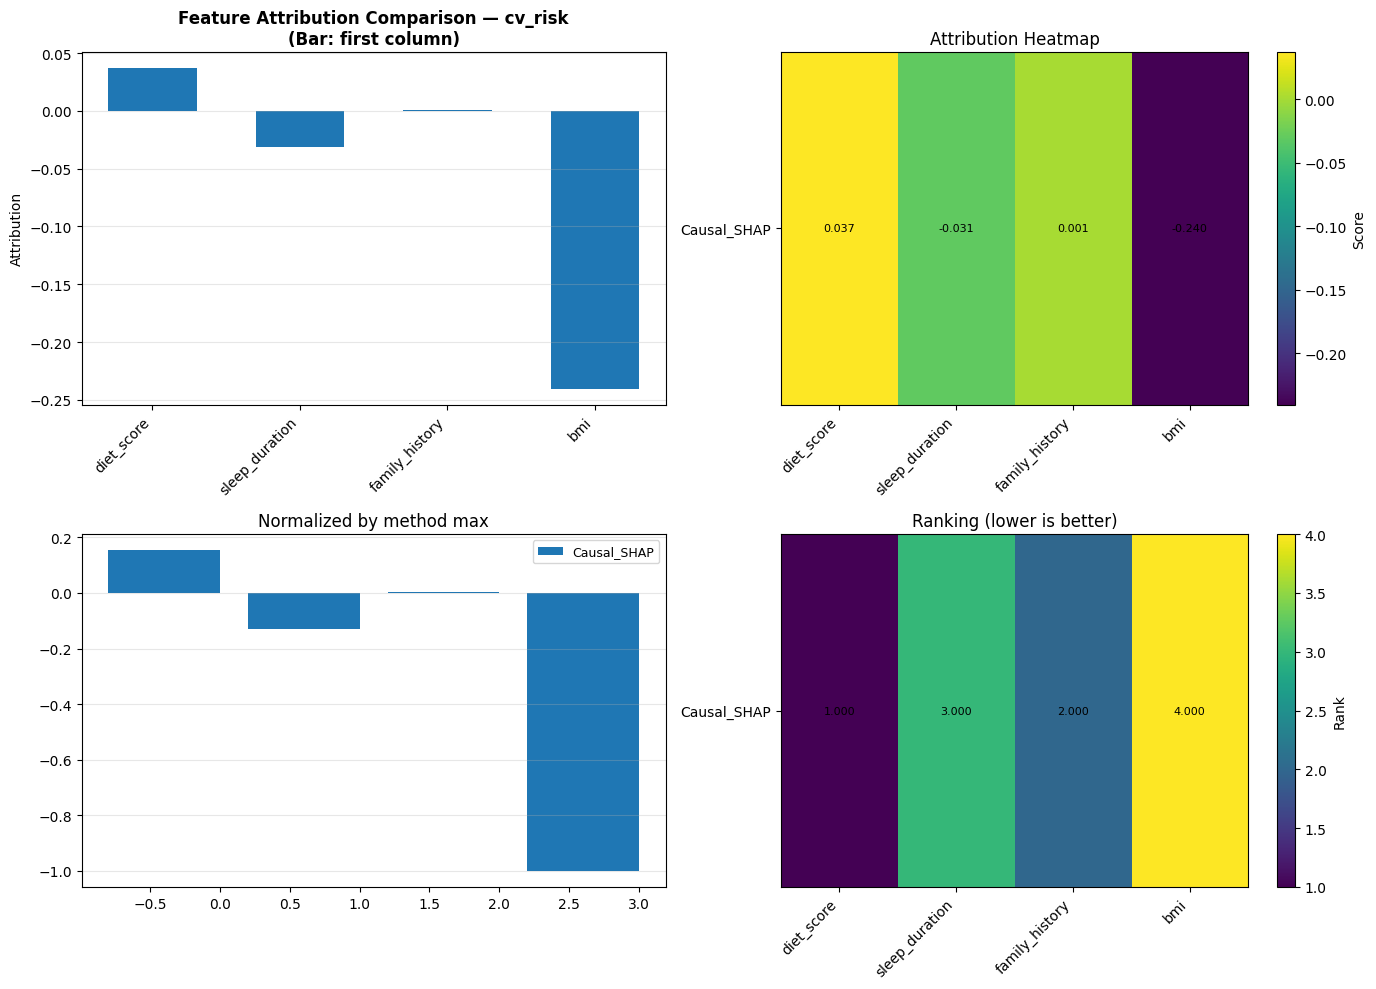


Causal SHAP (paper-faithful) on: lung_cancer_risk.csv
ERROR reading CSV: [Errno 2] No such file or directory: 'lung_cancer_risk.csv'


In [4]:
"""
Causal SHAP (paper-faithful) for CSVs with auto regression/classification
- Tested for:
  /mnt/data/cv_risk.csv          (continuous target: cv_risk)
  /mnt/data/lung_cancer_risk.csv (continuous target: lung_cancer_risk)
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set, Optional
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import f1_score, accuracy_score, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.utils.multiclass import type_of_target
import networkx as nx

try:
    from xgboost import XGBClassifier, XGBRegressor
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

CONFIG = {
    'ALPHA_PC': 0.1,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5
}
np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])

COMMON_TARGET_NAMES = ["target","label","y","class","outcome",
                       "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
                       "cancer","lung_cancer","has_cancer","diagnosis"]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns: return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map: return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed(df: pd.DataFrame) -> pd.DataFrame:
    return df[[c for c in df.columns if not re.match(r'^unnamed', c, re.I)]].copy()

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num

class CausalStructure:
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("ok PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        G = nx.DiGraph(); G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j: continue
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        dags = []
        names = self.feature_names; n = len(names)
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))
        for _ in range(max(1, n_samples)):
            G = nx.DiGraph(); G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            for u, v in undirected:
                if rng.random() < 0.5: G.add_edge(u, v)
                else: G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v); G.add_edge(v, u)
                    else: G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G): break
                    else: G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags

class LinearMechanisms:
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag; self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}; self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try: self.topo = list(nx.topological_sort(self.dag))
        except Exception: self.topo = self._safe_topo()
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {"parents": [], "intercept": float(X[var].mean()),
                                        "coef": None, "sigma": float(X[var].std(ddof=0))}
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {"parents": parents, "intercept": float(lr.intercept_),
                                        "coef": lr.coef_.astype(float), "sigma": float(np.std(resid, ddof=0))}
        return self

    def _safe_topo(self) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready: ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S: x_new[var] = float(x_obs[var]); continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                pvals = np.array([x_new.get(p, x_obs[p]) for p in mech["parents"]])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new

class CausalEffects:
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total effects W_i ...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")

            # (A) Edge weights among features
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12:
                    G.add_edge(u, v, weight=w)

            # (B) Direct edges into Y: Y ~ all features
            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12:
                    G.add_edge(feat, "Y", weight=float(w))

            # (C) Sum of path products i -> ... -> Y
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0
                        ok = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed:
                                ok = False
                                break
                            prod *= ed["weight"]
                        if ok:
                            total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("ok W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}


class CausalSHAP:
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series, task: str):
        self.model = model; self.structure = structure
        self.X_train = X_train; self.y_train = y_train
        self.features = list(X_train.columns); self.task = task

        print("\nFitting SEMs & sampling DAGs ...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()
        self._Ef_cache = None
        print("ok CausalSHAP ready")

    def _predict_scalar(self, X_mat: np.ndarray) -> float:
        if self.task == "classification":
            proba = self.model.predict_proba(X_mat)[0]
            return float(proba[np.argmax(proba)])  # predicted class prob (paper used f(x) scalar)
        else:  # regression
            return float(self.model.predict(X_mat)[0])

    def _Ef(self) -> float:
        if self._Ef_cache is None:
            if self.task == "classification":
                P = self.model.predict_proba(self.X_train.values)
                self._Ef_cache = float(P.max(axis=1).mean())  # mean predicted-class prob
            else:
                preds = self.model.predict(self.X_train.values)
                self._Ef_cache = float(np.mean(preds))
        return self._Ef_cache

    def _vc(self, S: Set[str], x: pd.Series, M: int) -> float:
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                total += self._predict_scalar(X_mat)
        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

    def explain_instance(self, x: pd.Series, n_perms: int=None, M: int=None) -> pd.Series:
        if n_perms is None: n_perms = CONFIG['MAX_PERM']
        if M is None: M = CONFIG['M_RESAMPLES']

        fx = self._predict_scalar(pd.DataFrame([x], columns=self.features).values)
        phi = np.zeros(len(self.features), dtype=float)

        for _ in range(n_perms):
            perm = rng.permutation(self.features)
            S: Set[str] = set()
            v_prev = self._vc(S, x, M)
            for feat in perm:
                S_next = S | {feat}
                v_curr = self._vc(S_next, x, M)
                delta = v_curr - v_prev
                phi[self.features.index(feat)] += self.gamma[feat] * delta
                v_prev, S = v_curr, S_next

        phi /= n_perms

        sum_phi_c = float(np.sum(phi))
        if abs(sum_phi_c) > 1e-12:
            Ef = self._Ef()
            phi = phi * ((fx - Ef) / sum_phi_c)
        return pd.Series(phi, index=self.features, name="Causal_SHAP")

    def explain_global(self, X_test: pd.DataFrame, k: int=None) -> pd.Series:
        if k is None: k = CONFIG['GLOBAL_K']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)
        print(f"\nComputing global Causal SHAP over {k} instances ...")
        exps = []
        for t, i in enumerate(idx, 1):
            if t % 5 == 0: print(f"  {t}/{k}")
            exps.append(self.explain_instance(X_test.iloc[i], n_perms=max(10, CONFIG['MAX_PERM']//4)))
        return pd.concat(exps, axis=1).mean(axis=1).rename("Causal_SHAP_Global")

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1])); ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax); cbar.set_label(cbar_label)
    ax.set_title(title)

def plot_comparison(df: pd.DataFrame, title="Feature Attribution Comparison"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes[0, 0].bar(np.arange(df.shape[0]), df.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar: first column)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xticks(np.arange(df.shape[0])); axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution'); axes[0, 0].grid(axis='y', alpha=0.3)
    annotate_heatmap(axes[0, 1], df.T, 'Attribution Heatmap', 'Score')
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col],
                       width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized by method max'); axes[1, 0].legend(fontsize=9); axes[1, 0].grid(axis='y', alpha=0.3)
    ranks = df.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Ranking (lower is better)', 'Rank')
    fig.tight_layout(); return fig

def plot_causal_graph(G: nx.DiGraph, title="Discovered Causal Graph (PC)"):
    # Work on a copy
    G = G.copy()

    components = list(nx.weakly_connected_components(G))
    pos = {}
    x_offset = 0.0

    for comp in components:
        sub = G.subgraph(comp)
        sub_pos = nx.spring_layout(sub, seed=CONFIG['RANDOM_SEED'], k=0.7)

        # shift each component horizontally so they don't overlap
        for n, (x, y) in sub_pos.items():
            pos[n] = (x + x_offset, y)

        x_offset += 3.0  # spacing between component blocks

    import matplotlib.pyplot as plt
    cmap = plt.cm.Set3  # nice pastel qualitative palette
    n_comp = max(1, len(components))

    comp_color_map = {}
    for i, comp in enumerate(components):
        color = cmap(float(i) / max(1, n_comp - 1)) if n_comp > 1 else cmap(0.2)
        for node in comp:
            comp_color_map[node] = color

    node_colors = [comp_color_map[n] for n in G.nodes()]

    plt.figure(figsize=(8, 6))

    # Nodes: coloured fill, black border
    nx.draw_networkx_nodes(
        G, pos,
        node_color=node_colors,
        edgecolors="black",
        linewidths=1.8,
        node_size=1400,
        alpha=0.95,
    )

    # Edges: dark for contrast
    nx.draw_networkx_edges(
        G, pos,
        edge_color="black",
        arrows=True,
        width=2.6,
        arrowsize=23,
        arrowstyle="-|>",
        connectionstyle="arc3,rad=0.12",
    )

    # Labels
    nx.draw_networkx_labels(
        G, pos,
        font_size=11,
        font_weight="bold",
    )

    plt.title(title, fontsize=15, fontweight="bold", pad=12)
    plt.axis("off")
    plt.tight_layout()
    return plt.gcf()


def run_causal_shap_on_csv(csv_path: str, dataset_name: Optional[str]=None, target_hint: Optional[str]=None, test_size: float=0.25):
    print("\n" + "="*72)
    print(f"Causal SHAP (paper-faithful) on: {csv_path}")
    print("="*72)

    try:
        raw = pd.read_csv(csv_path)
    except Exception as e:
        print(f"ERROR reading CSV: {e}"); return

    raw = drop_unnamed(raw)  # drop index columns like 'Unnamed: 0'
    if dataset_name is None:
        dataset_name = csv_path.split("/")[-1].split(".")[0]

    tgt_col = detect_target_column(raw, target_hint)
    if tgt_col not in raw.columns:
        print("ERROR: target column not found."); return

    y_raw = raw[tgt_col].copy()
    X_raw = raw.drop(columns=[tgt_col])

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan).fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary","multiclass"]:
        task = "classification"
        y_vec = y_raw.astype(int).values
    else:
        task = "regression"
        y_vec = pd.to_numeric(y_raw, errors="coerce").values
        if np.isnan(y_vec).any():
            print("ERROR: target has non-numeric values that cannot be coerced."); return

    strat = y_vec if (task=="classification" and len(np.unique(y_vec))>1) else None
    X_train, X_test, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=CONFIG['RANDOM_SEED'], stratify=strat
    )

    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    Xte = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

    if task=="classification":
        n_classes = int(len(np.unique(y_train)))
        if HAVE_XGB:
            model = XGBClassifier(
                n_estimators=160, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED'], verbosity=0,
                objective="multi:softprob" if n_classes>2 else "binary:logistic",
                num_class=n_classes if n_classes>2 else None
            )
            print("Using XGBoost (classification)")
        else:
            model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (classification)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred); f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}, classes={n_classes}")
    else:
        if HAVE_XGB:
            model = XGBRegressor(
                n_estimators=200, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED']
            )
            print("Using XGBoost (regression)")
        else:
            model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (regression)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred); mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Step 1: PC discovery
    print("\n" + "-"*64)
    print("Step 1: Causal discovery (PC)")
    print("-"*64)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph: {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} edges")
    fig = plot_causal_graph(G_skel, title=f"Discovered Causal Graph (PC) — {dataset_name}")
    fig.savefig(
    f'causal_graph_{dataset_name}.png',
    dpi=300,                 # was 150
    bbox_inches='tight',
    facecolor="white"        # ensures no transparent background in PDFs
)

    # Step 2: Causal SHAP
    print("\n" + "-"*64)
    print("Step 2: Causal SHAP")
    print("-"*64)
    cshap = CausalSHAP(model, cs, Xtr, pd.Series(y_train), task=task)
    print("\nTotal causal effects W_i and gamma_i:")
    for f in Xtr.columns:
        print(f"  {f:20s}  W={cshap.effects.effects[f]:10.6f}   γ={cshap.gamma[f]:.6f}")

    glob = cshap.explain_global(Xte, k=min(CONFIG['GLOBAL_K'], len(Xte)))

    # Step 3: Save/plot comparison (Causal_SHAP only by default for regression)
    cols = {"Causal_SHAP": glob}
    df = pd.DataFrame(cols)
    df.to_csv(f"attribution_scores_{dataset_name}.csv", index=True)
    print("\n" + "-"*64)
    print("Step 3: Comparison & Save")
    print("-"*64)
    print(df.round(6).to_string())
    print(f"\nSaved: attribution_scores_{dataset_name}.csv")

    fig2 = plot_comparison(df, title=f"Feature Attribution Comparison — {dataset_name}")
    fig2.savefig(f'attribution_comparison_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'attribution_comparison_{dataset_name}.png'")

    try: plt.show()
    except Exception: pass

def main():
    run_causal_shap_on_csv("../../datasets/cv_risk.csv", dataset_name="cv_risk")
    run_causal_shap_on_csv("lung_cancer_risk.csv", dataset_name="lung_cancer_risk")

if __name__ == "__main__":
    main()


Causal SHAP (paper-faithful) on: ../datasets/lung_cancer_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.7086, MAE=1.5185

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 3 features...
✓ PC completed -> CPDAG
Graph: 3 nodes, 2 edges

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i:
  smoking               W=  2.818595   γ=0.588029
  stress                W=  1.696499   γ=0.353932
  drink_coffee          W=  0.278200   γ=0.058039

Computing global Causal SHAP over 30 instances ...
  5/30
  10/30
  15/30
  20/30
  25/30
  30/30

----------------------------------------------------------------

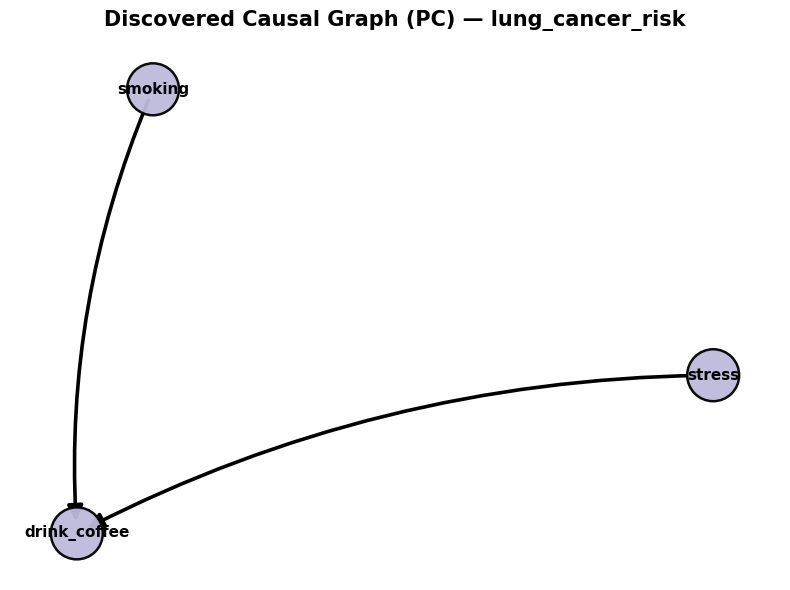

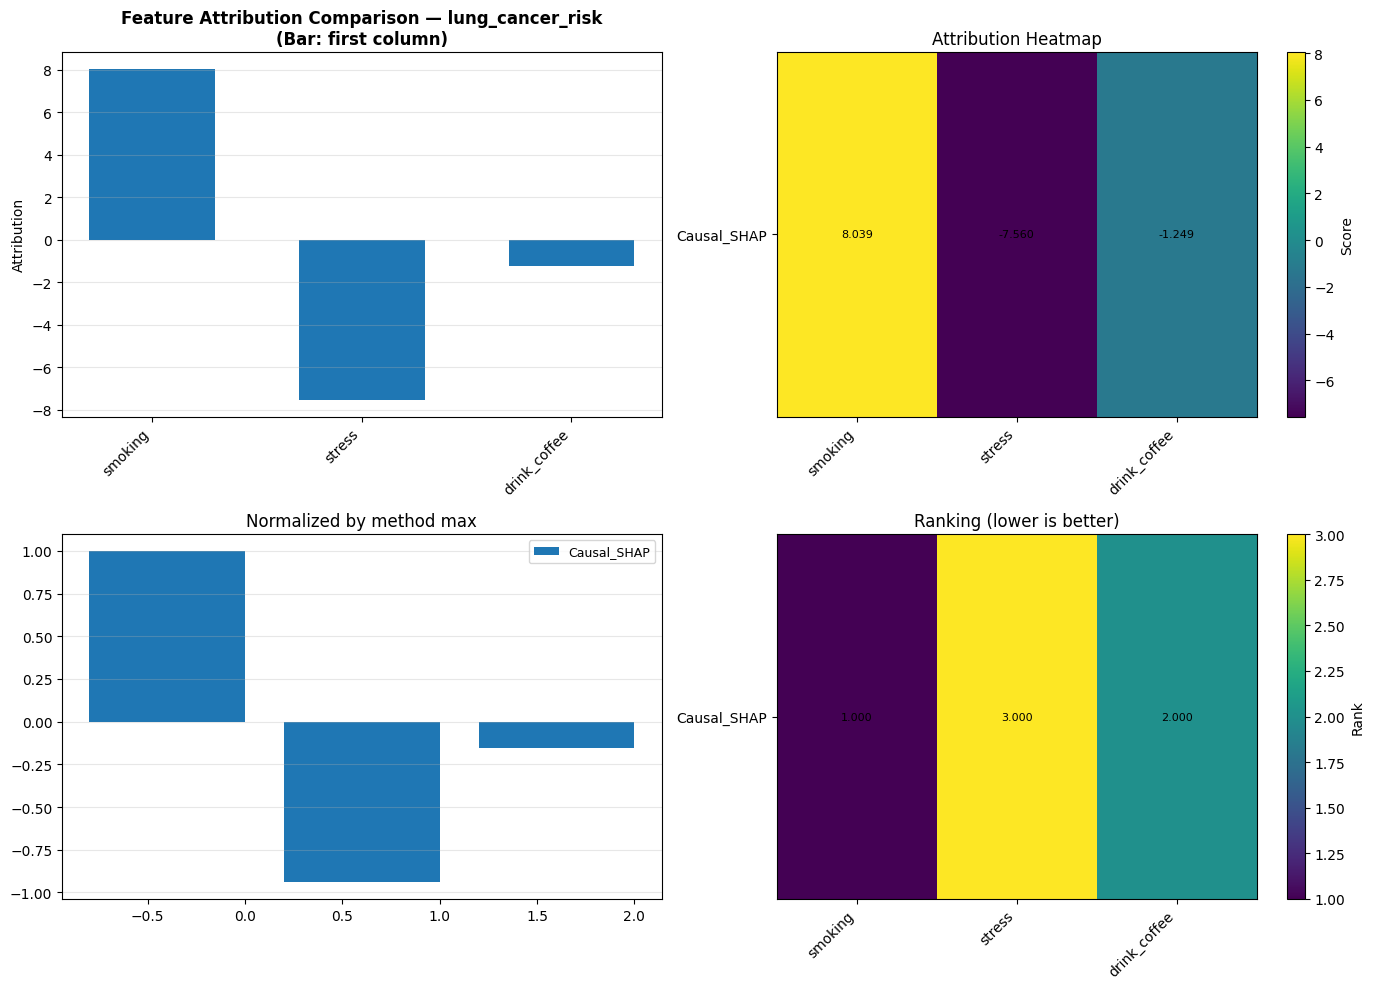

In [5]:
"""
Causal SHAP (paper-faithful) for CSVs with auto regression/classification
- Tested for:
  /mnt/data/cv_risk.csv          (continuous target: cv_risk)
  /mnt/data/lung_cancer_risk.csv (continuous target: lung_cancer_risk)
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set, Optional
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import f1_score, accuracy_score, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.utils.multiclass import type_of_target
import networkx as nx

try:
    from xgboost import XGBClassifier, XGBRegressor
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

CONFIG = {
    'ALPHA_PC': 0.1,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5
}
np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])

COMMON_TARGET_NAMES = ["target","label","y","class","outcome",
                       "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
                       "cancer","lung_cancer","has_cancer","diagnosis"]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns: return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map: return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed(df: pd.DataFrame) -> pd.DataFrame:
    return df[[c for c in df.columns if not re.match(r'^unnamed', c, re.I)]].copy()

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num

class CausalStructure:
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("ok PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        G = nx.DiGraph(); G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j: continue
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        dags = []
        names = self.feature_names; n = len(names)
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))
        for _ in range(max(1, n_samples)):
            G = nx.DiGraph(); G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            for u, v in undirected:
                if rng.random() < 0.5: G.add_edge(u, v)
                else: G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v); G.add_edge(v, u)
                    else: G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G): break
                    else: G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags

class LinearMechanisms:
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag; self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}; self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try: self.topo = list(nx.topological_sort(self.dag))
        except Exception: self.topo = self._safe_topo()
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {"parents": [], "intercept": float(X[var].mean()),
                                        "coef": None, "sigma": float(X[var].std(ddof=0))}
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {"parents": parents, "intercept": float(lr.intercept_),
                                        "coef": lr.coef_.astype(float), "sigma": float(np.std(resid, ddof=0))}
        return self

    def _safe_topo(self) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready: ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S: x_new[var] = float(x_obs[var]); continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                pvals = np.array([x_new.get(p, x_obs[p]) for p in mech["parents"]])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new

class CausalEffects:
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total effects W_i ...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")

            # (A) Edge weights among features
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12:
                    G.add_edge(u, v, weight=w)

            # (B) Direct edges into Y: Y ~ all features
            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12:
                    G.add_edge(feat, "Y", weight=float(w))

            # (C) Sum of path products i -> ... -> Y
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0
                        ok = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed:
                                ok = False
                                break
                            prod *= ed["weight"]
                        if ok:
                            total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("ok W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}


class CausalSHAP:
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series, task: str):
        self.model = model; self.structure = structure
        self.X_train = X_train; self.y_train = y_train
        self.features = list(X_train.columns); self.task = task

        print("\nFitting SEMs & sampling DAGs ...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()
        self._Ef_cache = None
        print("ok CausalSHAP ready")

    def _predict_scalar(self, X_mat: np.ndarray) -> float:
        if self.task == "classification":
            proba = self.model.predict_proba(X_mat)[0]
            return float(proba[np.argmax(proba)])  # predicted class prob (paper used f(x) scalar)
        else:  # regression
            return float(self.model.predict(X_mat)[0])

    def _Ef(self) -> float:
        if self._Ef_cache is None:
            if self.task == "classification":
                P = self.model.predict_proba(self.X_train.values)
                self._Ef_cache = float(P.max(axis=1).mean())  # mean predicted-class prob
            else:
                preds = self.model.predict(self.X_train.values)
                self._Ef_cache = float(np.mean(preds))
        return self._Ef_cache

    def _vc(self, S: Set[str], x: pd.Series, M: int) -> float:
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                total += self._predict_scalar(X_mat)
        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

    def explain_instance(self, x: pd.Series, n_perms: int=None, M: int=None) -> pd.Series:
        if n_perms is None: n_perms = CONFIG['MAX_PERM']
        if M is None: M = CONFIG['M_RESAMPLES']

        fx = self._predict_scalar(pd.DataFrame([x], columns=self.features).values)
        phi = np.zeros(len(self.features), dtype=float)

        for _ in range(n_perms):
            perm = rng.permutation(self.features)
            S: Set[str] = set()
            v_prev = self._vc(S, x, M)
            for feat in perm:
                S_next = S | {feat}
                v_curr = self._vc(S_next, x, M)
                delta = v_curr - v_prev
                phi[self.features.index(feat)] += self.gamma[feat] * delta
                v_prev, S = v_curr, S_next

        phi /= n_perms

        sum_phi_c = float(np.sum(phi))
        if abs(sum_phi_c) > 1e-12:
            Ef = self._Ef()
            phi = phi * ((fx - Ef) / sum_phi_c)
        return pd.Series(phi, index=self.features, name="Causal_SHAP")

    def explain_global(self, X_test: pd.DataFrame, k: int=None) -> pd.Series:
        if k is None: k = CONFIG['GLOBAL_K']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)
        print(f"\nComputing global Causal SHAP over {k} instances ...")
        exps = []
        for t, i in enumerate(idx, 1):
            if t % 5 == 0: print(f"  {t}/{k}")
            exps.append(self.explain_instance(X_test.iloc[i], n_perms=max(10, CONFIG['MAX_PERM']//4)))
        return pd.concat(exps, axis=1).mean(axis=1).rename("Causal_SHAP_Global")

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1])); ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax); cbar.set_label(cbar_label)
    ax.set_title(title)

def plot_comparison(df: pd.DataFrame, title="Feature Attribution Comparison"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes[0, 0].bar(np.arange(df.shape[0]), df.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar: first column)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xticks(np.arange(df.shape[0])); axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution'); axes[0, 0].grid(axis='y', alpha=0.3)
    annotate_heatmap(axes[0, 1], df.T, 'Attribution Heatmap', 'Score')
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col],
                       width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized by method max'); axes[1, 0].legend(fontsize=9); axes[1, 0].grid(axis='y', alpha=0.3)
    ranks = df.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Ranking (lower is better)', 'Rank')
    fig.tight_layout(); return fig

def plot_causal_graph(G: nx.DiGraph, title="Discovered Causal Graph (PC)"):
    # Work on a copy
    G = G.copy()

    components = list(nx.weakly_connected_components(G))
    pos = {}
    x_offset = 0.0

    for comp in components:
        sub = G.subgraph(comp)
        sub_pos = nx.spring_layout(sub, seed=CONFIG['RANDOM_SEED'], k=0.7)

        # shift each component horizontally so they don't overlap
        for n, (x, y) in sub_pos.items():
            pos[n] = (x + x_offset, y)

        x_offset += 3.0  # spacing between component blocks

    import matplotlib.pyplot as plt
    cmap = plt.cm.Set3  # nice pastel qualitative palette
    n_comp = max(1, len(components))

    comp_color_map = {}
    for i, comp in enumerate(components):
        color = cmap(float(i) / max(1, n_comp - 1)) if n_comp > 1 else cmap(0.2)
        for node in comp:
            comp_color_map[node] = color

    node_colors = [comp_color_map[n] for n in G.nodes()]

    plt.figure(figsize=(8, 6))

    # Nodes: coloured fill, black border
    nx.draw_networkx_nodes(
        G, pos,
        node_color=node_colors,
        edgecolors="black",
        linewidths=1.8,
        node_size=1400,
        alpha=0.95,
    )

    # Edges: dark for contrast
    nx.draw_networkx_edges(
        G, pos,
        edge_color="black",
        arrows=True,
        width=2.6,
        arrowsize=23,
        arrowstyle="-|>",
        connectionstyle="arc3,rad=0.12",
    )

    # Labels
    nx.draw_networkx_labels(
        G, pos,
        font_size=11,
        font_weight="bold",
    )

    plt.title(title, fontsize=15, fontweight="bold", pad=12)
    plt.axis("off")
    plt.tight_layout()
    return plt.gcf()


def run_causal_shap_on_csv(csv_path: str, dataset_name: Optional[str]=None, target_hint: Optional[str]=None, test_size: float=0.25):
    print("\n" + "="*72)
    print(f"Causal SHAP (paper-faithful) on: {csv_path}")
    print("="*72)

    try:
        raw = pd.read_csv(csv_path)
    except Exception as e:
        print(f"ERROR reading CSV: {e}"); return

    raw = drop_unnamed(raw)  # drop index columns like 'Unnamed: 0'
    if dataset_name is None:
        dataset_name = csv_path.split("/")[-1].split(".")[0]

    tgt_col = detect_target_column(raw, target_hint)
    if tgt_col not in raw.columns:
        print("ERROR: target column not found."); return

    y_raw = raw[tgt_col].copy()
    X_raw = raw.drop(columns=[tgt_col])

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan).fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary","multiclass"]:
        task = "classification"
        y_vec = y_raw.astype(int).values
    else:
        task = "regression"
        y_vec = pd.to_numeric(y_raw, errors="coerce").values
        if np.isnan(y_vec).any():
            print("ERROR: target has non-numeric values that cannot be coerced."); return

    strat = y_vec if (task=="classification" and len(np.unique(y_vec))>1) else None
    X_train, X_test, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=CONFIG['RANDOM_SEED'], stratify=strat
    )

    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    Xte = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

    if task=="classification":
        n_classes = int(len(np.unique(y_train)))
        if HAVE_XGB:
            model = XGBClassifier(
                n_estimators=160, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED'], verbosity=0,
                objective="multi:softprob" if n_classes>2 else "binary:logistic",
                num_class=n_classes if n_classes>2 else None
            )
            print("Using XGBoost (classification)")
        else:
            model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (classification)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred); f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}, classes={n_classes}")
    else:
        if HAVE_XGB:
            model = XGBRegressor(
                n_estimators=200, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED']
            )
            print("Using XGBoost (regression)")
        else:
            model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (regression)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred); mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Step 1: PC discovery
    print("\n" + "-"*64)
    print("Step 1: Causal discovery (PC)")
    print("-"*64)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph: {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} edges")
    fig = plot_causal_graph(G_skel, title=f"Discovered Causal Graph (PC) — {dataset_name}")
    fig.savefig(
    f'causal_graph_{dataset_name}.png',
    dpi=300,                 # was 150
    bbox_inches='tight',
    facecolor="white"        # ensures no transparent background in PDFs
)

    # Step 2: Causal SHAP
    print("\n" + "-"*64)
    print("Step 2: Causal SHAP")
    print("-"*64)
    cshap = CausalSHAP(model, cs, Xtr, pd.Series(y_train), task=task)
    print("\nTotal causal effects W_i and gamma_i:")
    for f in Xtr.columns:
        print(f"  {f:20s}  W={cshap.effects.effects[f]:10.6f}   γ={cshap.gamma[f]:.6f}")

    glob = cshap.explain_global(Xte, k=min(CONFIG['GLOBAL_K'], len(Xte)))

    # Step 3: Save/plot comparison (Causal_SHAP only by default for regression)
    cols = {"Causal_SHAP": glob}
    df = pd.DataFrame(cols)
    df.to_csv(f"attribution_scores_{dataset_name}.csv", index=True)
    print("\n" + "-"*64)
    print("Step 3: Comparison & Save")
    print("-"*64)
    print(df.round(6).to_string())
    print(f"\nSaved: attribution_scores_{dataset_name}.csv")

    fig2 = plot_comparison(df, title=f"Feature Attribution Comparison — {dataset_name}")
    fig2.savefig(f'attribution_comparison_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'attribution_comparison_{dataset_name}.png'")

    try: plt.show()
    except Exception: pass

def main():
    run_causal_shap_on_csv("../../datasets/lung_cancer_risk.csv", dataset_name="lung_cancer_risk")

if __name__ == "__main__":
    main()


Causal SHAP (paper-faithful) on: ../datasets/cv_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.6623, MAE=1.3549

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 4 features...
✓ PC completed -> CPDAG
Graph: 4 nodes, 6 edges

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i:
  diet_score            W=  0.633641   γ=0.126076
  sleep_duration        W=  1.511709   γ=0.300785
  family_history        W=  0.248761   γ=0.049496
  bmi                   W=  2.631762   γ=0.523643

Computing global Causal SHAP over 30 instances ...
  5/30
  10/30
  15/30
  20/30
  25/30
  30/30

-----------------------

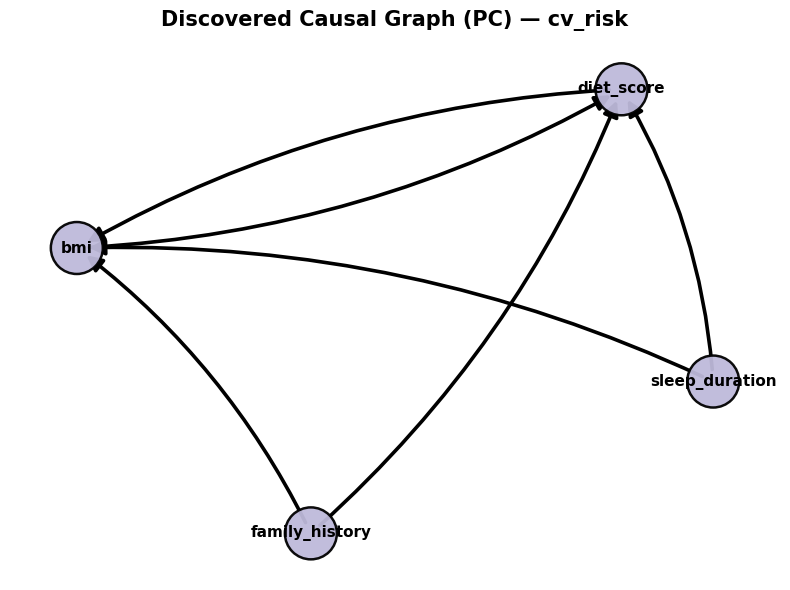

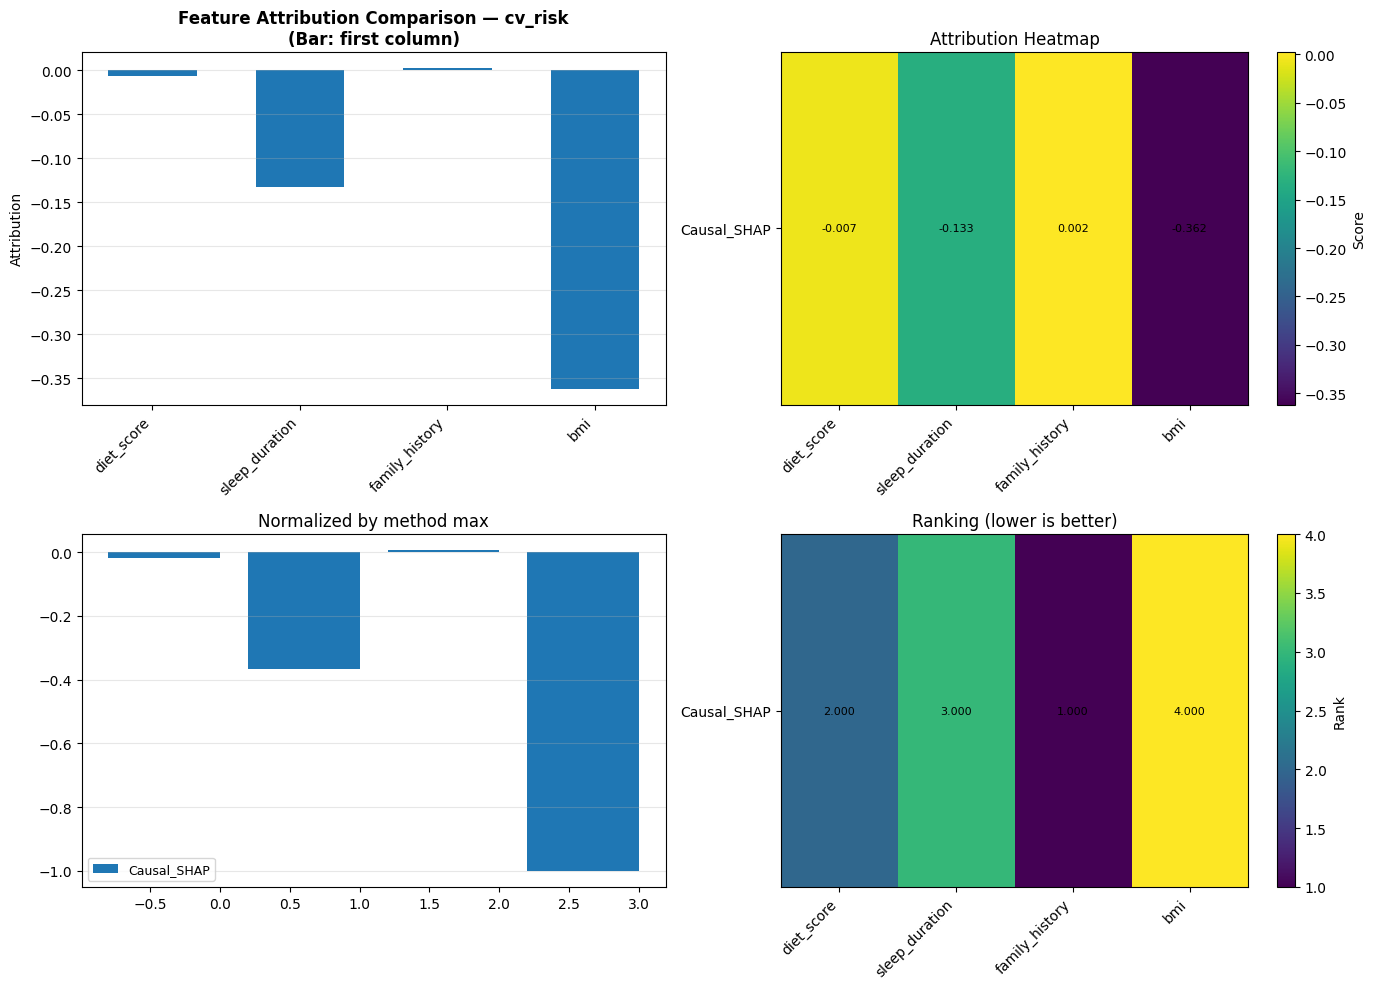


Causal SHAP (paper-faithful) on: ../datasets/lung_cancer_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.7086, MAE=1.5185

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 3 features...
✓ PC completed -> CPDAG
Graph: 3 nodes, 6 edges

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i:
  smoking               W=  3.142424   γ=0.426209
  stress                W=  1.963131   γ=0.266260
  drink_coffee          W=  2.267417   γ=0.307531

Computing global Causal SHAP over 30 instances ...
  5/30
  10/30
  15/30
  20/30
  25/30
  30/30

----------------------------------------------------------------

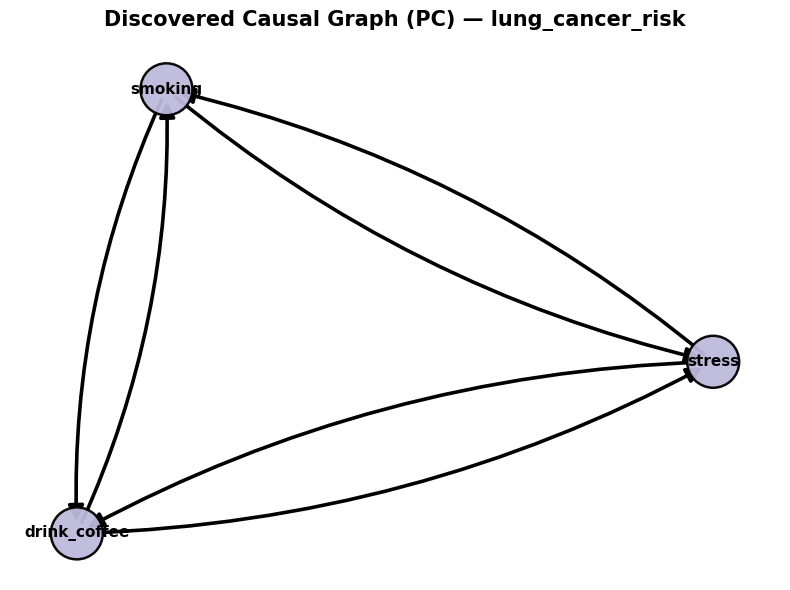

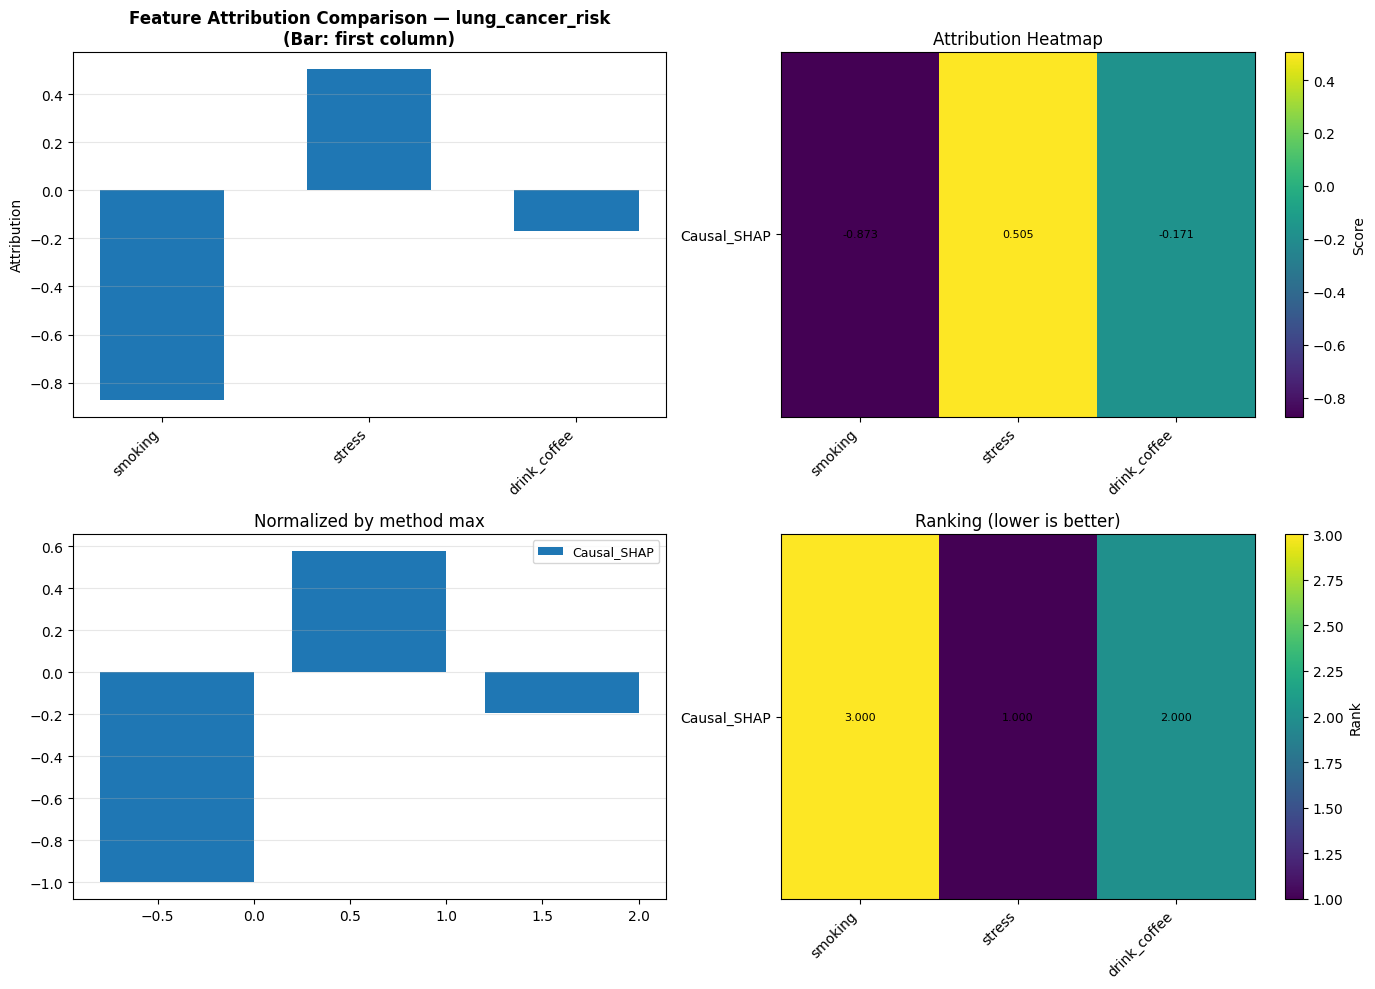

In [6]:
"""
Causal SHAP (paper-faithful) for CSVs with auto regression/classification
- Tested for:
  /mnt/data/cv_risk.csv          (continuous target: cv_risk)
  /mnt/data/lung_cancer_risk.csv (continuous target: lung_cancer_risk)
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set, Optional
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import f1_score, accuracy_score, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.utils.multiclass import type_of_target
import networkx as nx

try:
    from xgboost import XGBClassifier, XGBRegressor
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

CONFIG = {
    'ALPHA_PC': 0.9,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5
}
np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])

COMMON_TARGET_NAMES = ["target","label","y","class","outcome",
                       "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
                       "cancer","lung_cancer","has_cancer","diagnosis"]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns: return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map: return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed(df: pd.DataFrame) -> pd.DataFrame:
    return df[[c for c in df.columns if not re.match(r'^unnamed', c, re.I)]].copy()

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num

class CausalStructure:
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("ok PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        G = nx.DiGraph(); G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j: continue
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        dags = []
        names = self.feature_names; n = len(names)
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))
        for _ in range(max(1, n_samples)):
            G = nx.DiGraph(); G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            for u, v in undirected:
                if rng.random() < 0.5: G.add_edge(u, v)
                else: G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v); G.add_edge(v, u)
                    else: G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G): break
                    else: G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags

class LinearMechanisms:
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag; self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}; self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try: self.topo = list(nx.topological_sort(self.dag))
        except Exception: self.topo = self._safe_topo()
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {"parents": [], "intercept": float(X[var].mean()),
                                        "coef": None, "sigma": float(X[var].std(ddof=0))}
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {"parents": parents, "intercept": float(lr.intercept_),
                                        "coef": lr.coef_.astype(float), "sigma": float(np.std(resid, ddof=0))}
        return self

    def _safe_topo(self) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready: ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S: x_new[var] = float(x_obs[var]); continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                pvals = np.array([x_new.get(p, x_obs[p]) for p in mech["parents"]])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new

class CausalEffects:
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total effects W_i ...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")

            # (A) Edge weights among features
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12:
                    G.add_edge(u, v, weight=w)

            # (B) Direct edges into Y: Y ~ all features
            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12:
                    G.add_edge(feat, "Y", weight=float(w))

            # (C) Sum of path products i -> ... -> Y
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0
                        ok = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed:
                                ok = False
                                break
                            prod *= ed["weight"]
                        if ok:
                            total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("ok W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}


class CausalSHAP:
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series, task: str):
        self.model = model; self.structure = structure
        self.X_train = X_train; self.y_train = y_train
        self.features = list(X_train.columns); self.task = task

        print("\nFitting SEMs & sampling DAGs ...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()
        self._Ef_cache = None
        print("ok CausalSHAP ready")

    def _predict_scalar(self, X_mat: np.ndarray) -> float:
        if self.task == "classification":
            proba = self.model.predict_proba(X_mat)[0]
            return float(proba[np.argmax(proba)])  # predicted class prob (paper used f(x) scalar)
        else:  # regression
            return float(self.model.predict(X_mat)[0])

    def _Ef(self) -> float:
        if self._Ef_cache is None:
            if self.task == "classification":
                P = self.model.predict_proba(self.X_train.values)
                self._Ef_cache = float(P.max(axis=1).mean())  # mean predicted-class prob
            else:
                preds = self.model.predict(self.X_train.values)
                self._Ef_cache = float(np.mean(preds))
        return self._Ef_cache

    def _vc(self, S: Set[str], x: pd.Series, M: int) -> float:
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                total += self._predict_scalar(X_mat)
        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

    def explain_instance(self, x: pd.Series, n_perms: int=None, M: int=None) -> pd.Series:
        if n_perms is None: n_perms = CONFIG['MAX_PERM']
        if M is None: M = CONFIG['M_RESAMPLES']

        fx = self._predict_scalar(pd.DataFrame([x], columns=self.features).values)
        phi = np.zeros(len(self.features), dtype=float)

        for _ in range(n_perms):
            perm = rng.permutation(self.features)
            S: Set[str] = set()
            v_prev = self._vc(S, x, M)
            for feat in perm:
                S_next = S | {feat}
                v_curr = self._vc(S_next, x, M)
                delta = v_curr - v_prev
                phi[self.features.index(feat)] += self.gamma[feat] * delta
                v_prev, S = v_curr, S_next

        phi /= n_perms

        sum_phi_c = float(np.sum(phi))
        if abs(sum_phi_c) > 1e-12:
            Ef = self._Ef()
            phi = phi * ((fx - Ef) / sum_phi_c)
        return pd.Series(phi, index=self.features, name="Causal_SHAP")

    def explain_global(self, X_test: pd.DataFrame, k: int=None) -> pd.Series:
        if k is None: k = CONFIG['GLOBAL_K']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)
        print(f"\nComputing global Causal SHAP over {k} instances ...")
        exps = []
        for t, i in enumerate(idx, 1):
            if t % 5 == 0: print(f"  {t}/{k}")
            exps.append(self.explain_instance(X_test.iloc[i], n_perms=max(10, CONFIG['MAX_PERM']//4)))
        return pd.concat(exps, axis=1).mean(axis=1).rename("Causal_SHAP_Global")

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1])); ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax); cbar.set_label(cbar_label)
    ax.set_title(title)

def plot_comparison(df: pd.DataFrame, title="Feature Attribution Comparison"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes[0, 0].bar(np.arange(df.shape[0]), df.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar: first column)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xticks(np.arange(df.shape[0])); axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution'); axes[0, 0].grid(axis='y', alpha=0.3)
    annotate_heatmap(axes[0, 1], df.T, 'Attribution Heatmap', 'Score')
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col],
                       width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized by method max'); axes[1, 0].legend(fontsize=9); axes[1, 0].grid(axis='y', alpha=0.3)
    ranks = df.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Ranking (lower is better)', 'Rank')
    fig.tight_layout(); return fig

def plot_causal_graph(G: nx.DiGraph, title="Discovered Causal Graph (PC)"):
    # Work on a copy
    G = G.copy()

    components = list(nx.weakly_connected_components(G))
    pos = {}
    x_offset = 0.0

    for comp in components:
        sub = G.subgraph(comp)
        sub_pos = nx.spring_layout(sub, seed=CONFIG['RANDOM_SEED'], k=0.7)

        # shift each component horizontally so they don't overlap
        for n, (x, y) in sub_pos.items():
            pos[n] = (x + x_offset, y)

        x_offset += 3.0  # spacing between component blocks

    import matplotlib.pyplot as plt
    cmap = plt.cm.Set3  # nice pastel qualitative palette
    n_comp = max(1, len(components))

    comp_color_map = {}
    for i, comp in enumerate(components):
        color = cmap(float(i) / max(1, n_comp - 1)) if n_comp > 1 else cmap(0.2)
        for node in comp:
            comp_color_map[node] = color

    node_colors = [comp_color_map[n] for n in G.nodes()]

    plt.figure(figsize=(8, 6))

    # Nodes: coloured fill, black border
    nx.draw_networkx_nodes(
        G, pos,
        node_color=node_colors,
        edgecolors="black",
        linewidths=1.8,
        node_size=1400,
        alpha=0.95,
    )

    # Edges: dark for contrast
    nx.draw_networkx_edges(
        G, pos,
        edge_color="black",
        arrows=True,
        width=2.6,
        arrowsize=23,
        arrowstyle="-|>",
        connectionstyle="arc3,rad=0.12",
    )

    # Labels
    nx.draw_networkx_labels(
        G, pos,
        font_size=11,
        font_weight="bold",
    )

    plt.title(title, fontsize=15, fontweight="bold", pad=12)
    plt.axis("off")
    plt.tight_layout()
    return plt.gcf()


def run_causal_shap_on_csv(csv_path: str, dataset_name: Optional[str]=None, target_hint: Optional[str]=None, test_size: float=0.25):
    print("\n" + "="*72)
    print(f"Causal SHAP (paper-faithful) on: {csv_path}")
    print("="*72)

    try:
        raw = pd.read_csv(csv_path)
    except Exception as e:
        print(f"ERROR reading CSV: {e}"); return

    raw = drop_unnamed(raw)  # drop index columns like 'Unnamed: 0'
    if dataset_name is None:
        dataset_name = csv_path.split("/")[-1].split(".")[0]

    tgt_col = detect_target_column(raw, target_hint)
    if tgt_col not in raw.columns:
        print("ERROR: target column not found."); return

    y_raw = raw[tgt_col].copy()
    X_raw = raw.drop(columns=[tgt_col])

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan).fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary","multiclass"]:
        task = "classification"
        y_vec = y_raw.astype(int).values
    else:
        task = "regression"
        y_vec = pd.to_numeric(y_raw, errors="coerce").values
        if np.isnan(y_vec).any():
            print("ERROR: target has non-numeric values that cannot be coerced."); return

    strat = y_vec if (task=="classification" and len(np.unique(y_vec))>1) else None
    X_train, X_test, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=CONFIG['RANDOM_SEED'], stratify=strat
    )

    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    Xte = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

    if task=="classification":
        n_classes = int(len(np.unique(y_train)))
        if HAVE_XGB:
            model = XGBClassifier(
                n_estimators=160, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED'], verbosity=0,
                objective="multi:softprob" if n_classes>2 else "binary:logistic",
                num_class=n_classes if n_classes>2 else None
            )
            print("Using XGBoost (classification)")
        else:
            model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (classification)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred); f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}, classes={n_classes}")
    else:
        if HAVE_XGB:
            model = XGBRegressor(
                n_estimators=200, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED']
            )
            print("Using XGBoost (regression)")
        else:
            model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (regression)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred); mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Step 1: PC discovery
    print("\n" + "-"*64)
    print("Step 1: Causal discovery (PC)")
    print("-"*64)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph: {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} edges")
    fig = plot_causal_graph(G_skel, title=f"Discovered Causal Graph (PC) — {dataset_name}")
    fig.savefig(
    f'causal_graph_{dataset_name}.png',
    dpi=300,                 # was 150
    bbox_inches='tight',
    facecolor="white"        # ensures no transparent background in PDFs
)

    # Step 2: Causal SHAP
    print("\n" + "-"*64)
    print("Step 2: Causal SHAP")
    print("-"*64)
    cshap = CausalSHAP(model, cs, Xtr, pd.Series(y_train), task=task)
    print("\nTotal causal effects W_i and gamma_i:")
    for f in Xtr.columns:
        print(f"  {f:20s}  W={cshap.effects.effects[f]:10.6f}   γ={cshap.gamma[f]:.6f}")

    glob = cshap.explain_global(Xte, k=min(CONFIG['GLOBAL_K'], len(Xte)))

    # Step 3: Save/plot comparison (Causal_SHAP only by default for regression)
    cols = {"Causal_SHAP": glob}
    df = pd.DataFrame(cols)
    df.to_csv(f"attribution_scores_{dataset_name}.csv", index=True)
    print("\n" + "-"*64)
    print("Step 3: Comparison & Save")
    print("-"*64)
    print(df.round(6).to_string())
    print(f"\nSaved: attribution_scores_{dataset_name}.csv")

    fig2 = plot_comparison(df, title=f"Feature Attribution Comparison — {dataset_name}")
    fig2.savefig(f'attribution_comparison_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'attribution_comparison_{dataset_name}.png'")

    try: plt.show()
    except Exception: pass

def main():
    run_causal_shap_on_csv("../../datasets/cv_risk.csv", dataset_name="cv_risk")
    run_causal_shap_on_csv("../../datasets/lung_cancer_risk.csv", dataset_name="lung_cancer_risk")

if __name__ == "__main__":
    main()


Causal SHAP (paper-faithful) on: ../datasets/cv_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.6623, MAE=1.3549

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 4 features...
✓ PC completed -> CPDAG
Graph (features only): 4 nodes, 2 edges

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i:
  diet_score            W=  1.557027   γ=0.268893
  sleep_duration        W=  1.514280   γ=0.261510
  family_history        W=  0.097514   γ=0.016840
  bmi                   W=  2.621693   γ=0.452757

----------------------------------------------------------------
Step 1b: Causal graph with target (edges 

✓ Saved 'causal_graph_cv_risk.png' with target node and W_i-based edges


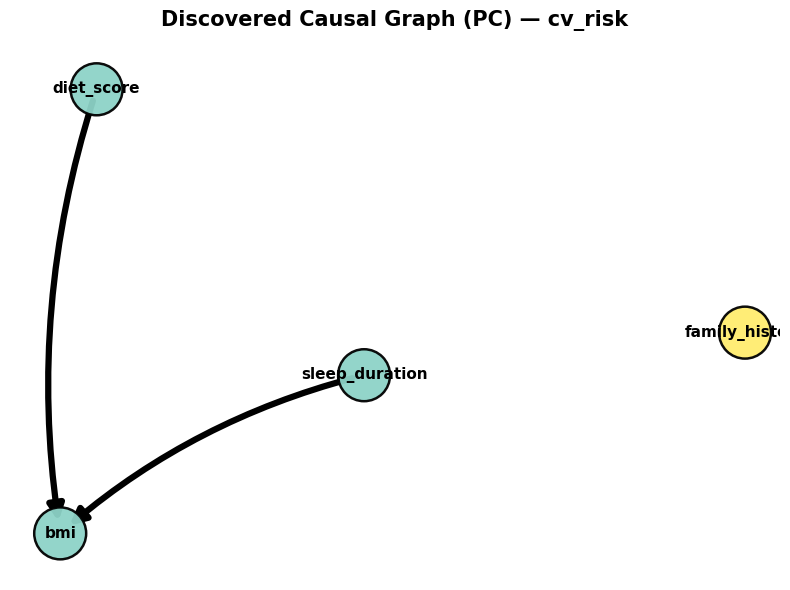

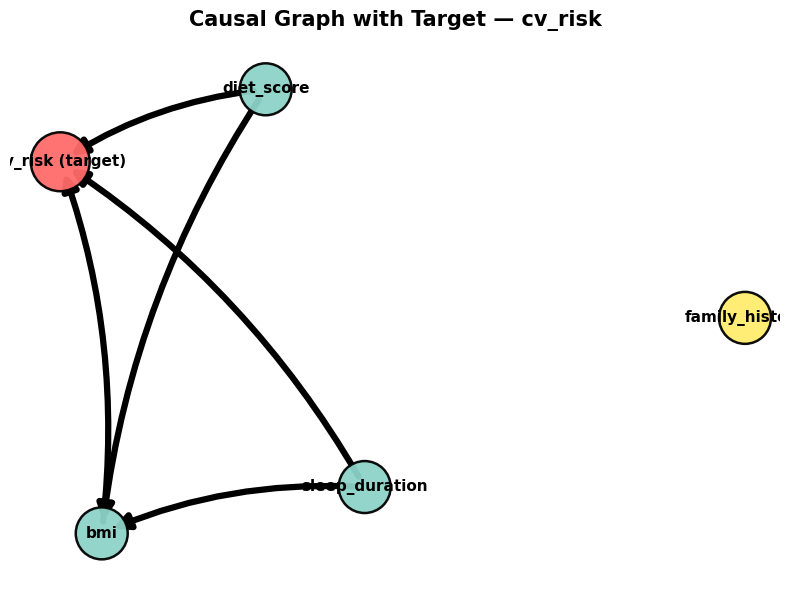


Causal SHAP (paper-faithful) on: ../datasets/lung_cancer_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.7086, MAE=1.5185

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 3 features...
✓ PC completed -> CPDAG
Graph (features only): 3 nodes, 2 edges

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i:
  smoking               W=  2.818595   γ=0.588029
  stress                W=  1.696499   γ=0.353932
  drink_coffee          W=  0.278200   γ=0.058039

----------------------------------------------------------------
Step 1b: Causal graph with target (edges only from causally contributing features)

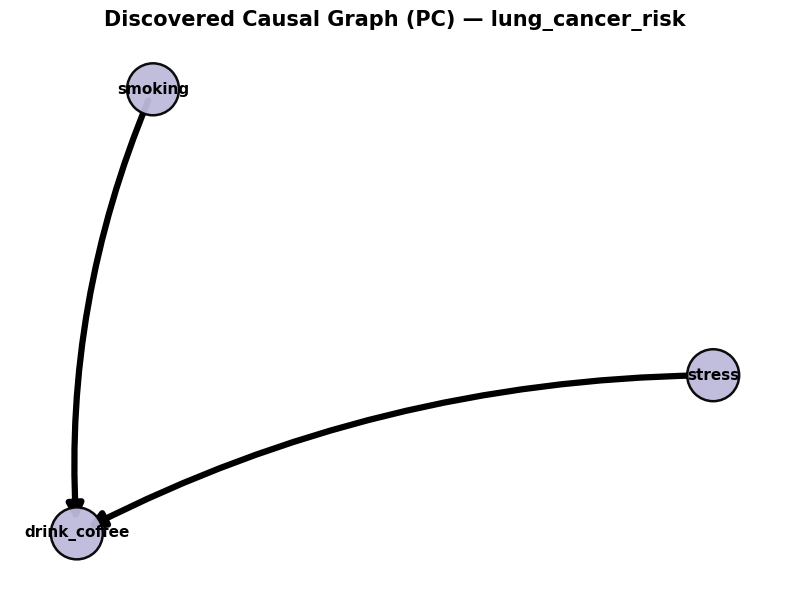

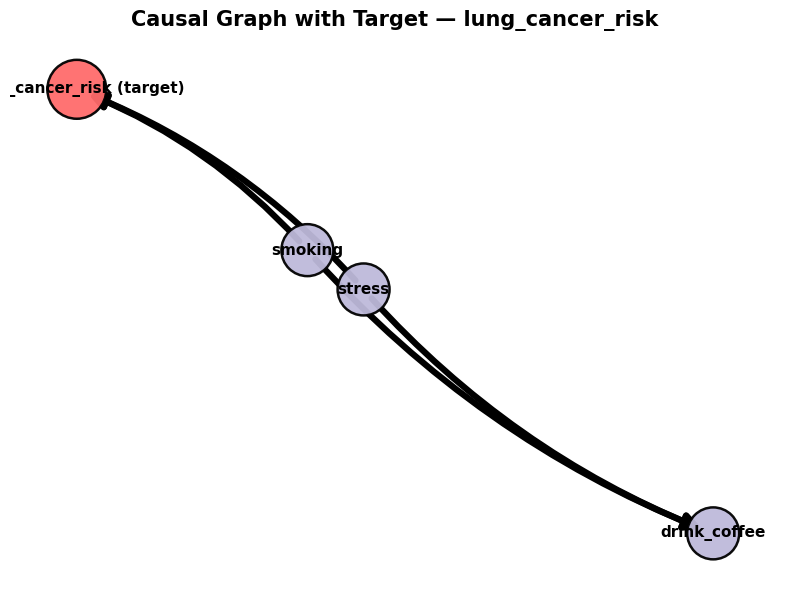

In [5]:
"""
Causal SHAP (paper-faithful) for CSVs with auto regression/classification
- Tested for:
  /mnt/data/cv_risk.csv          (continuous target: cv_risk)
  /mnt/data/lung_cancer_risk.csv (continuous target: lung_cancer_risk)
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set, Optional
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import f1_score, accuracy_score, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.utils.multiclass import type_of_target
import networkx as nx

try:
    from xgboost import XGBClassifier, XGBRegressor
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

CONFIG = {
    'ALPHA_PC': 0.1,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5
}
np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])

COMMON_TARGET_NAMES = ["target","label","y","class","outcome",
                       "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
                       "cancer","lung_cancer","has_cancer","diagnosis"]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns: return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map: return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed(df: pd.DataFrame) -> pd.DataFrame:
    return df[[c for c in df.columns if not re.match(r'^unnamed', c, re.I)]].copy()

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num

class CausalStructure:
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("ok PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        G = nx.DiGraph(); G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j: continue
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        dags = []
        names = self.feature_names; n = len(names)
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))
        for _ in range(max(1, n_samples)):
            G = nx.DiGraph(); G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            for u, v in undirected:
                if rng.random() < 0.5: G.add_edge(u, v)
                else: G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v); G.add_edge(v, u)
                    else: G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G): break
                    else: G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags

class LinearMechanisms:
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag; self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}; self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try: self.topo = list(nx.topological_sort(self.dag))
        except Exception: self.topo = self._safe_topo()
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {"parents": [], "intercept": float(X[var].mean()),
                                        "coef": None, "sigma": float(X[var].std(ddof=0))}
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {"parents": parents, "intercept": float(lr.intercept_),
                                        "coef": lr.coef_.astype(float), "sigma": float(np.std(resid, ddof=0))}
        return self

    def _safe_topo(self) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready: ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S: x_new[var] = float(x_obs[var]); continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                pvals = np.array([x_new.get(p, x_obs[p]) for p in mech["parents"]])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new

class CausalEffects:
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total effects W_i ...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")

            # (A) Edge weights among features
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12:
                    G.add_edge(u, v, weight=w)

            # (B) Direct edges into Y: Y ~ all features
            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12:
                    G.add_edge(feat, "Y", weight=float(w))

            # (C) Sum of path products i -> ... -> Y
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0
                        ok = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed:
                                ok = False
                                break
                            prod *= ed["weight"]
                        if ok:
                            total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("ok W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}


class CausalSHAP:
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series, task: str):
        self.model = model; self.structure = structure
        self.X_train = X_train; self.y_train = y_train
        self.features = list(X_train.columns); self.task = task

        print("\nFitting SEMs & sampling DAGs ...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()
        self._Ef_cache = None
        print("ok CausalSHAP ready")

    def _predict_scalar(self, X_mat: np.ndarray) -> float:
        if self.task == "classification":
            proba = self.model.predict_proba(X_mat)[0]
            return float(proba[np.argmax(proba)])  # predicted class prob (paper used f(x) scalar)
        else:  # regression
            return float(self.model.predict(X_mat)[0])

    def _Ef(self) -> float:
        if self._Ef_cache is None:
            if self.task == "classification":
                P = self.model.predict_proba(self.X_train.values)
                self._Ef_cache = float(P.max(axis=1).mean())  # mean predicted-class prob
            else:
                preds = self.model.predict(self.X_train.values)
                self._Ef_cache = float(np.mean(preds))
        return self._Ef_cache

    def _vc(self, S: Set[str], x: pd.Series, M: int) -> float:
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                total += self._predict_scalar(X_mat)
        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

    def explain_instance(self, x: pd.Series, n_perms: int=None, M: int=None) -> pd.Series:
        if n_perms is None: n_perms = CONFIG['MAX_PERM']
        if M is None: M = CONFIG['M_RESAMPLES']

        fx = self._predict_scalar(pd.DataFrame([x], columns=self.features).values)
        phi = np.zeros(len(self.features), dtype=float)

        for _ in range(n_perms):
            perm = rng.permutation(self.features)
            S: Set[str] = set()
            v_prev = self._vc(S, x, M)
            for feat in perm:
                S_next = S | {feat}
                v_curr = self._vc(S_next, x, M)
                delta = v_curr - v_prev
                phi[self.features.index(feat)] += self.gamma[feat] * delta
                v_prev, S = v_curr, S_next

        phi /= n_perms

        sum_phi_c = float(np.sum(phi))
        if abs(sum_phi_c) > 1e-12:
            Ef = self._Ef()
            phi = phi * ((fx - Ef) / sum_phi_c)
        return pd.Series(phi, index=self.features, name="Causal_SHAP")

    def explain_global(self, X_test: pd.DataFrame, k: int=None) -> pd.Series:
        if k is None: k = CONFIG['GLOBAL_K']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)
        print(f"\nComputing global Causal SHAP over {k} instances ...")
        exps = []
        for t, i in enumerate(idx, 1):
            if t % 5 == 0: print(f"  {t}/{k}")
            exps.append(self.explain_instance(X_test.iloc[i], n_perms=max(10, CONFIG['MAX_PERM']//4)))
        return pd.concat(exps, axis=1).mean(axis=1).rename("Causal_SHAP_Global")

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1])); ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax); cbar.set_label(cbar_label)
    ax.set_title(title)

def plot_comparison(df: pd.DataFrame, title="Feature Attribution Comparison"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes[0, 0].bar(np.arange(df.shape[0]), df.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar: first column)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xticks(np.arange(df.shape[0])); axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution'); axes[0, 0].grid(axis='y', alpha=0.3)
    annotate_heatmap(axes[0, 1], df.T, 'Attribution Heatmap', 'Score')
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col],
                       width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized by method max'); axes[1, 0].legend(fontsize=9); axes[1, 0].grid(axis='y', alpha=0.3)
    ranks = df.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Ranking (lower is better)', 'Rank')
    fig.tight_layout(); return fig

def plot_causal_graph(G: nx.DiGraph, title="Discovered Causal Graph (PC)", target_name: Optional[str] = None):
    # Work on a copy
    G = G.copy()

    components = list(nx.weakly_connected_components(G))
    pos = {}
    x_offset = 0.0

    for comp in components:
        sub = G.subgraph(comp)
        sub_pos = nx.spring_layout(sub, seed=CONFIG['RANDOM_SEED'], k=0.7)

        # shift each component horizontally so they don't overlap
        for n, (x, y) in sub_pos.items():
            pos[n] = (x + x_offset, y)

        x_offset += 3.0  # spacing between component blocks

    import matplotlib.pyplot as plt
    cmap = plt.cm.Set3  # nice pastel qualitative palette
    n_comp = max(1, len(components))

    comp_color_map = {}
    for i, comp in enumerate(components):
        color = cmap(float(i) / max(1, n_comp - 1)) if n_comp > 1 else cmap(0.2)
        for node in comp:
            comp_color_map[node] = color

    default_color = cmap(0.0)

    node_colors = []
    node_sizes = []
    for n in G.nodes():
        if target_name is not None and n == target_name:
            # Target node: distinct colour + bigger node
            node_colors.append("#ff6b6b")   # reddish
            node_sizes.append(1800)
        else:
            node_colors.append(comp_color_map.get(n, default_color))
            node_sizes.append(1400)

    # Labels: annotate target
    labels = {n: (f"{n} (target)" if (target_name is not None and n == target_name) else n)
              for n in G.nodes()}

    plt.figure(figsize=(8, 6))

    # Nodes: coloured fill, black border
    nx.draw_networkx_nodes(
        G, pos,
        node_color=node_colors,
        edgecolors="black",
        linewidths=1.8,
        node_size=node_sizes,
        alpha=0.95,
    )

    # Edges: use weights if present for width, otherwise default
    widths = []
    for u, v, data in G.edges(data=True):
        w = data.get("weight", 1.0)
        widths.append(1.5 + 3.0 * (abs(w) / (1e-12 + max(1.0, abs(w)))))  # gentle scaling

    nx.draw_networkx_edges(
        G, pos,
        edge_color="black",
        arrows=True,
        width=widths if widths else 2.6,
        arrowsize=23,
        arrowstyle="-|>",
        connectionstyle="arc3,rad=0.12",
    )

    # Labels
    nx.draw_networkx_labels(
        G, pos,
        labels=labels,
        font_size=11,
        font_weight="bold",
    )

    plt.title(title, fontsize=15, fontweight="bold", pad=12)
    plt.axis("off")
    plt.tight_layout()
    return plt.gcf()


def run_causal_shap_on_csv(csv_path: str, dataset_name: Optional[str]=None, target_hint: Optional[str]=None, test_size: float=0.25):
    print("\n" + "="*72)
    print(f"Causal SHAP (paper-faithful) on: {csv_path}")
    print("="*72)

    try:
        raw = pd.read_csv(csv_path)
    except Exception as e:
        print(f"ERROR reading CSV: {e}"); return

    raw = drop_unnamed(raw)  # drop index columns like 'Unnamed: 0'
    if dataset_name is None:
        dataset_name = csv_path.split("/")[-1].split(".")[0]

    tgt_col = detect_target_column(raw, target_hint)
    if tgt_col not in raw.columns:
        print("ERROR: target column not found."); return

    y_raw = raw[tgt_col].copy()
    X_raw = raw.drop(columns=[tgt_col])

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan).fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary","multiclass"]:
        task = "classification"
        y_vec = y_raw.astype(int).values
    else:
        task = "regression"
        y_vec = pd.to_numeric(y_raw, errors="coerce").values
        if np.isnan(y_vec).any():
            print("ERROR: target has non-numeric values that cannot be coerced."); return

    strat = y_vec if (task=="classification" and len(np.unique(y_vec))>1) else None
    X_train, X_test, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=CONFIG['RANDOM_SEED'], stratify=strat
    )

    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    Xte = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

    if task=="classification":
        n_classes = int(len(np.unique(y_train)))
        if HAVE_XGB:
            model = XGBClassifier(
                n_estimators=160, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED'], verbosity=0,
                objective="multi:softprob" if n_classes>2 else "binary:logistic",
                num_class=n_classes if n_classes>2 else None
            )
            print("Using XGBoost (classification)")
        else:
            model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (classification)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred); f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}, classes={n_classes}")
    else:
        if HAVE_XGB:
            model = XGBRegressor(
                n_estimators=200, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED']
            )
            print("Using XGBoost (regression)")
        else:
            model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (regression)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred); mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Step 1: PC discovery
    print("\n" + "-"*64)
    print("Step 1: Causal discovery (PC)")
    print("-"*64)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph (features only): {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} edges")

    fig = plot_causal_graph(G_skel, title=f"Discovered Causal Graph (PC) — {dataset_name}")
    fig.savefig(
    f'causal_graph_{dataset_name}.png',
    dpi=300,                 # was 150
    bbox_inches='tight',
    facecolor="white"        # ensures no transparent background in PDFs
)

    # Step 2: Causal SHAP
    print("\n" + "-"*64)
    print("Step 2: Causal SHAP")
    print("-"*64)
    cshap = CausalSHAP(model, cs, Xtr, pd.Series(y_train), task=task)
    print("\nTotal causal effects W_i and gamma_i:")
    for f in Xtr.columns:
        print(f"  {f:20s}  W={cshap.effects.effects[f]:10.6f}   γ={cshap.gamma[f]:.6f}")

    print("\n" + "-"*64)
    print("Step 1b: Causal graph with target (edges only from causally contributing features)")
    print("-"*64)

    # Base graph is the PC skeleton among features
    G_aug = G_skel.copy()

    # Add target node
    G_aug.add_node(tgt_col)

    # Use IDA-style total effects W_i to decide which features connect to target
    W = cshap.effects.effects  # dict: feature -> W_i
    abs_W = {f: abs(v) for f, v in W.items()}
    max_W = max(abs_W.values()) if abs_W else 0.0

    if max_W <= 0.0:
        print("Warning: all W_i are zero; no feature-target edges will be added.")
    else:
        # Threshold: only features with |W_i| >= 1% of max(|W|) get an edge
        thr = 0.10 * max_W
        print(f"Using threshold |W_i| >= {thr:.6f} for edges into target '{tgt_col}'")

        for feat, wi in W.items():
            if abs(wi) >= thr:
                # Add directed edge feat -> target, weighted by W_i
                G_aug.add_edge(feat, tgt_col, weight=float(wi))

    print(f"Graph (with target): {G_aug.number_of_nodes()} nodes, {G_aug.number_of_edges()} edges")

    fig = plot_causal_graph(
        G_aug,
        title=f"Causal Graph with Target — {dataset_name}",
        target_name=tgt_col
    )
    fig.savefig(
        f'causal_graph_{dataset_name}.png',
        dpi=300,
        bbox_inches='tight',
        facecolor="white"
    )
    print(f"Saved 'causal_graph_{dataset_name}.png' with target node and W_i-based edges")


    try: plt.show()
    except Exception: pass

def main():
    run_causal_shap_on_csv("../../datasets/cv_risk.csv", dataset_name="cv_risk")
    run_causal_shap_on_csv("../../datasets/lung_cancer_risk.csv", dataset_name="lung_cancer_risk")

if __name__ == "__main__":
    main()


Causal SHAP (paper-faithful) on: ../datasets/cv_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.6623, MAE=1.3549

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 4 features...
✓ PC completed -> CPDAG
Graph (features only): 4 nodes, 6 edges

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i:
  diet_score            W=  0.633641   γ=0.126076
  sleep_duration        W=  1.511709   γ=0.300785
  family_history        W=  0.248761   γ=0.049496
  bmi                   W=  2.631762   γ=0.523643

----------------------------------------------------------------
Step 1b: Causal graph with target (edges 

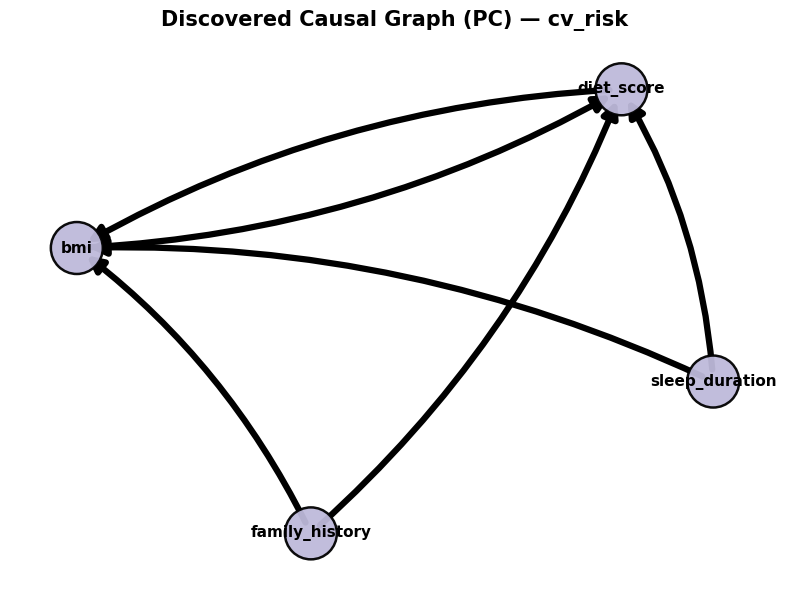

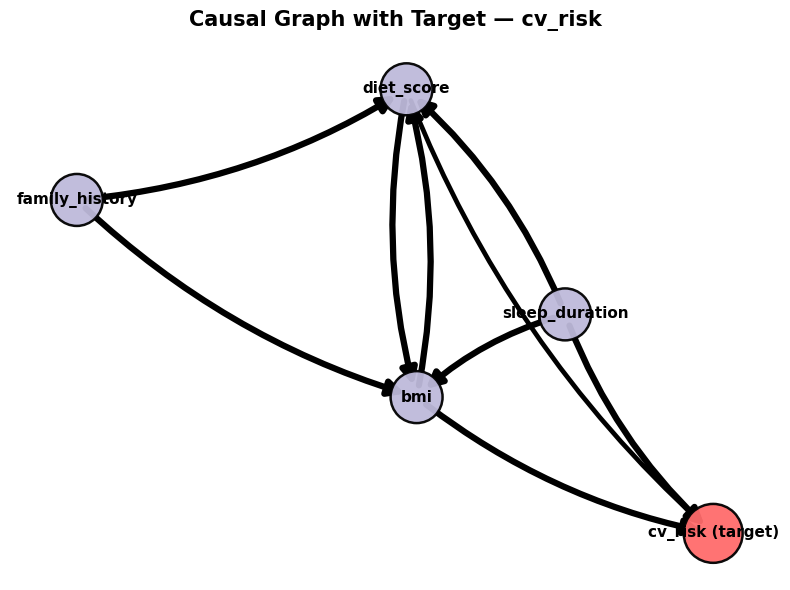


Causal SHAP (paper-faithful) on: ../datasets/lung_cancer_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.7086, MAE=1.5185

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 3 features...
✓ PC completed -> CPDAG
Graph (features only): 3 nodes, 6 edges

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i:
  smoking               W=  3.935780   γ=0.416855
  stress                W=  2.044886   γ=0.216582
  drink_coffee          W=  3.460940   γ=0.366563

----------------------------------------------------------------
Step 1b: Causal graph with target (edges only from causally contributing features)

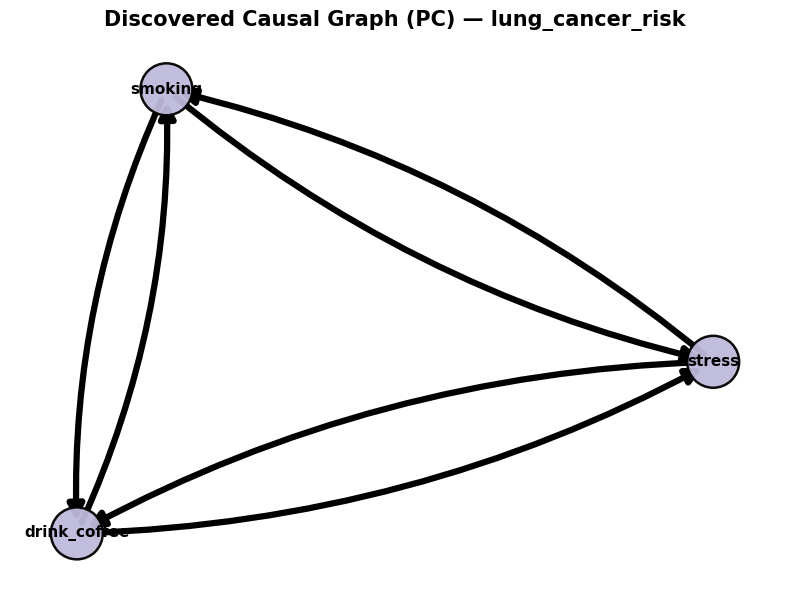

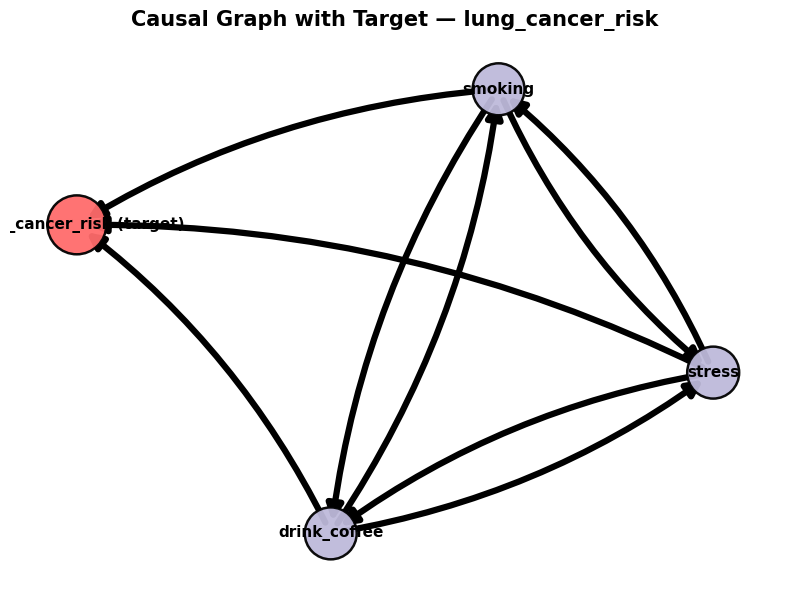

In [6]:
"""
Causal SHAP (paper-faithful) for CSVs with auto regression/classification
- Tested for:
  /mnt/data/cv_risk.csv          (continuous target: cv_risk)
  /mnt/data/lung_cancer_risk.csv (continuous target: lung_cancer_risk)
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set, Optional
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import f1_score, accuracy_score, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.utils.multiclass import type_of_target
import networkx as nx

try:
    from xgboost import XGBClassifier, XGBRegressor
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

CONFIG = {
    'ALPHA_PC': 0.9,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5
}
np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])

COMMON_TARGET_NAMES = ["target","label","y","class","outcome",
                       "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
                       "cancer","lung_cancer","has_cancer","diagnosis"]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns: return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map: return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed(df: pd.DataFrame) -> pd.DataFrame:
    return df[[c for c in df.columns if not re.match(r'^unnamed', c, re.I)]].copy()

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num

class CausalStructure:
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("ok PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        G = nx.DiGraph(); G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j: continue
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        dags = []
        names = self.feature_names; n = len(names)
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))
        for _ in range(max(1, n_samples)):
            G = nx.DiGraph(); G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            for u, v in undirected:
                if rng.random() < 0.5: G.add_edge(u, v)
                else: G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v); G.add_edge(v, u)
                    else: G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G): break
                    else: G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags

class LinearMechanisms:
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag; self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}; self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try: self.topo = list(nx.topological_sort(self.dag))
        except Exception: self.topo = self._safe_topo()
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {"parents": [], "intercept": float(X[var].mean()),
                                        "coef": None, "sigma": float(X[var].std(ddof=0))}
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {"parents": parents, "intercept": float(lr.intercept_),
                                        "coef": lr.coef_.astype(float), "sigma": float(np.std(resid, ddof=0))}
        return self

    def _safe_topo(self) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready: ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S: x_new[var] = float(x_obs[var]); continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                pvals = np.array([x_new.get(p, x_obs[p]) for p in mech["parents"]])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new

class CausalEffects:
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total effects W_i ...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")

            # (A) Edge weights among features
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12:
                    G.add_edge(u, v, weight=w)

            # (B) Direct edges into Y: Y ~ all features
            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12:
                    G.add_edge(feat, "Y", weight=float(w))

            # (C) Sum of path products i -> ... -> Y
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0
                        ok = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed:
                                ok = False
                                break
                            prod *= ed["weight"]
                        if ok:
                            total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("ok W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}


class CausalSHAP:
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series, task: str):
        self.model = model; self.structure = structure
        self.X_train = X_train; self.y_train = y_train
        self.features = list(X_train.columns); self.task = task

        print("\nFitting SEMs & sampling DAGs ...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()
        self._Ef_cache = None
        print("ok CausalSHAP ready")

    def _predict_scalar(self, X_mat: np.ndarray) -> float:
        if self.task == "classification":
            proba = self.model.predict_proba(X_mat)[0]
            return float(proba[np.argmax(proba)])  # predicted class prob (paper used f(x) scalar)
        else:  # regression
            return float(self.model.predict(X_mat)[0])

    def _Ef(self) -> float:
        if self._Ef_cache is None:
            if self.task == "classification":
                P = self.model.predict_proba(self.X_train.values)
                self._Ef_cache = float(P.max(axis=1).mean())  # mean predicted-class prob
            else:
                preds = self.model.predict(self.X_train.values)
                self._Ef_cache = float(np.mean(preds))
        return self._Ef_cache

    def _vc(self, S: Set[str], x: pd.Series, M: int) -> float:
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                total += self._predict_scalar(X_mat)
        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

    def explain_instance(self, x: pd.Series, n_perms: int=None, M: int=None) -> pd.Series:
        if n_perms is None: n_perms = CONFIG['MAX_PERM']
        if M is None: M = CONFIG['M_RESAMPLES']

        fx = self._predict_scalar(pd.DataFrame([x], columns=self.features).values)
        phi = np.zeros(len(self.features), dtype=float)

        for _ in range(n_perms):
            perm = rng.permutation(self.features)
            S: Set[str] = set()
            v_prev = self._vc(S, x, M)
            for feat in perm:
                S_next = S | {feat}
                v_curr = self._vc(S_next, x, M)
                delta = v_curr - v_prev
                phi[self.features.index(feat)] += self.gamma[feat] * delta
                v_prev, S = v_curr, S_next

        phi /= n_perms

        sum_phi_c = float(np.sum(phi))
        if abs(sum_phi_c) > 1e-12:
            Ef = self._Ef()
            phi = phi * ((fx - Ef) / sum_phi_c)
        return pd.Series(phi, index=self.features, name="Causal_SHAP")

    def explain_global(self, X_test: pd.DataFrame, k: int=None) -> pd.Series:
        if k is None: k = CONFIG['GLOBAL_K']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)
        print(f"\nComputing global Causal SHAP over {k} instances ...")
        exps = []
        for t, i in enumerate(idx, 1):
            if t % 5 == 0: print(f"  {t}/{k}")
            exps.append(self.explain_instance(X_test.iloc[i], n_perms=max(10, CONFIG['MAX_PERM']//4)))
        return pd.concat(exps, axis=1).mean(axis=1).rename("Causal_SHAP_Global")

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1])); ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax); cbar.set_label(cbar_label)
    ax.set_title(title)

def plot_comparison(df: pd.DataFrame, title="Feature Attribution Comparison"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes[0, 0].bar(np.arange(df.shape[0]), df.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar: first column)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xticks(np.arange(df.shape[0])); axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution'); axes[0, 0].grid(axis='y', alpha=0.3)
    annotate_heatmap(axes[0, 1], df.T, 'Attribution Heatmap', 'Score')
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col],
                       width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized by method max'); axes[1, 0].legend(fontsize=9); axes[1, 0].grid(axis='y', alpha=0.3)
    ranks = df.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Ranking (lower is better)', 'Rank')
    fig.tight_layout(); return fig

def plot_causal_graph(G: nx.DiGraph, title="Discovered Causal Graph (PC)", target_name: Optional[str] = None):
    # Work on a copy
    G = G.copy()

    components = list(nx.weakly_connected_components(G))
    pos = {}
    x_offset = 0.0

    for comp in components:
        sub = G.subgraph(comp)
        sub_pos = nx.spring_layout(sub, seed=CONFIG['RANDOM_SEED'], k=0.7)

        # shift each component horizontally so they don't overlap
        for n, (x, y) in sub_pos.items():
            pos[n] = (x + x_offset, y)

        x_offset += 3.0  # spacing between component blocks

    import matplotlib.pyplot as plt
    cmap = plt.cm.Set3  # nice pastel qualitative palette
    n_comp = max(1, len(components))

    comp_color_map = {}
    for i, comp in enumerate(components):
        color = cmap(float(i) / max(1, n_comp - 1)) if n_comp > 1 else cmap(0.2)
        for node in comp:
            comp_color_map[node] = color

    default_color = cmap(0.0)

    node_colors = []
    node_sizes = []
    for n in G.nodes():
        if target_name is not None and n == target_name:
            # Target node: distinct colour + bigger node
            node_colors.append("#ff6b6b")   # reddish
            node_sizes.append(1800)
        else:
            node_colors.append(comp_color_map.get(n, default_color))
            node_sizes.append(1400)

    # Labels: annotate target
    labels = {n: (f"{n} (target)" if (target_name is not None and n == target_name) else n)
              for n in G.nodes()}

    plt.figure(figsize=(8, 6))

    # Nodes: coloured fill, black border
    nx.draw_networkx_nodes(
        G, pos,
        node_color=node_colors,
        edgecolors="black",
        linewidths=1.8,
        node_size=node_sizes,
        alpha=0.95,
    )

    # Edges: use weights if present for width, otherwise default
    widths = []
    for u, v, data in G.edges(data=True):
        w = data.get("weight", 1.0)
        widths.append(1.5 + 3.0 * (abs(w) / (1e-12 + max(1.0, abs(w)))))  # gentle scaling

    nx.draw_networkx_edges(
        G, pos,
        edge_color="black",
        arrows=True,
        width=widths if widths else 2.6,
        arrowsize=23,
        arrowstyle="-|>",
        connectionstyle="arc3,rad=0.12",
    )

    # Labels
    nx.draw_networkx_labels(
        G, pos,
        labels=labels,
        font_size=11,
        font_weight="bold",
    )

    plt.title(title, fontsize=15, fontweight="bold", pad=12)
    plt.axis("off")
    plt.tight_layout()
    return plt.gcf()


def run_causal_shap_on_csv(csv_path: str, dataset_name: Optional[str]=None, target_hint: Optional[str]=None, test_size: float=0.25):
    print("\n" + "="*72)
    print(f"Causal SHAP (paper-faithful) on: {csv_path}")
    print("="*72)

    try:
        raw = pd.read_csv(csv_path)
    except Exception as e:
        print(f"ERROR reading CSV: {e}"); return

    raw = drop_unnamed(raw)  # drop index columns like 'Unnamed: 0'
    if dataset_name is None:
        dataset_name = csv_path.split("/")[-1].split(".")[0]

    tgt_col = detect_target_column(raw, target_hint)
    if tgt_col not in raw.columns:
        print("ERROR: target column not found."); return

    y_raw = raw[tgt_col].copy()
    X_raw = raw.drop(columns=[tgt_col])

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan).fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary","multiclass"]:
        task = "classification"
        y_vec = y_raw.astype(int).values
    else:
        task = "regression"
        y_vec = pd.to_numeric(y_raw, errors="coerce").values
        if np.isnan(y_vec).any():
            print("ERROR: target has non-numeric values that cannot be coerced."); return

    strat = y_vec if (task=="classification" and len(np.unique(y_vec))>1) else None
    X_train, X_test, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=CONFIG['RANDOM_SEED'], stratify=strat
    )

    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    Xte = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

    if task=="classification":
        n_classes = int(len(np.unique(y_train)))
        if HAVE_XGB:
            model = XGBClassifier(
                n_estimators=160, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED'], verbosity=0,
                objective="multi:softprob" if n_classes>2 else "binary:logistic",
                num_class=n_classes if n_classes>2 else None
            )
            print("Using XGBoost (classification)")
        else:
            model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (classification)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred); f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}, classes={n_classes}")
    else:
        if HAVE_XGB:
            model = XGBRegressor(
                n_estimators=200, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED']
            )
            print("Using XGBoost (regression)")
        else:
            model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (regression)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred); mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Step 1: PC discovery
    print("\n" + "-"*64)
    print("Step 1: Causal discovery (PC)")
    print("-"*64)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph (features only): {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} edges")

    fig = plot_causal_graph(G_skel, title=f"Discovered Causal Graph (PC) — {dataset_name}")
    fig.savefig(
    f'causal_graph_{dataset_name}.png',
    dpi=300,                 # was 150
    bbox_inches='tight',
    facecolor="white"        # ensures no transparent background in PDFs
)

    # Step 2: Causal SHAP
    print("\n" + "-"*64)
    print("Step 2: Causal SHAP")
    print("-"*64)
    cshap = CausalSHAP(model, cs, Xtr, pd.Series(y_train), task=task)
    print("\nTotal causal effects W_i and gamma_i:")
    for f in Xtr.columns:
        print(f"  {f:20s}  W={cshap.effects.effects[f]:10.6f}   γ={cshap.gamma[f]:.6f}")

    print("\n" + "-"*64)
    print("Step 1b: Causal graph with target (edges only from causally contributing features)")
    print("-"*64)

    # Base graph is the PC skeleton among features
    G_aug = G_skel.copy()

    # Add target node
    G_aug.add_node(tgt_col)

    # Use IDA-style total effects W_i to decide which features connect to target
    W = cshap.effects.effects  # dict: feature -> W_i
    abs_W = {f: abs(v) for f, v in W.items()}
    max_W = max(abs_W.values()) if abs_W else 0.0

    if max_W <= 0.0:
        print("Warning: all W_i are zero; no feature-target edges will be added.")
    else:
        # Threshold: only features with |W_i| >= 1% of max(|W|) get an edge
        thr = 0.10 * max_W
        print(f"Using threshold |W_i| >= {thr:.6f} for edges into target '{tgt_col}'")

        for feat, wi in W.items():
            if abs(wi) >= thr:
                # Add directed edge feat -> target, weighted by W_i
                G_aug.add_edge(feat, tgt_col, weight=float(wi))

    print(f"Graph (with target): {G_aug.number_of_nodes()} nodes, {G_aug.number_of_edges()} edges")

    fig = plot_causal_graph(
        G_aug,
        title=f"Causal Graph with Target — {dataset_name}",
        target_name=tgt_col
    )
    fig.savefig(
        f'causal_graph_{dataset_name}.png',
        dpi=300,
        bbox_inches='tight',
        facecolor="white"
    )
    print(f"Saved 'causal_graph_{dataset_name}.png' with target node and W_i-based edges")


    try: plt.show()
    except Exception: pass

def main():
    run_causal_shap_on_csv("../../datasets/cv_risk.csv", dataset_name="cv_risk")
    run_causal_shap_on_csv("../../datasets/lung_cancer_risk.csv", dataset_name="lung_cancer_risk")

if __name__ == "__main__":
    main()